Predicting Stock Market Prices	Implement rolling statistics computation and exponential moving average algorithms to analyze the smoothed behavior of TSLA closing prices, providing insight into short- and long-term price trends.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset and sort chronologically (critical for time-series windows)
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"Dataset Range: {df['Date'].min().date()} to {df['Date'].max().date()} ({len(df)} trading days)")
df.head()

Dataset Range: 2025-01-02 to 2025-05-14 (100 trading days)


,Date,Open,High,Low,Close,Volume
0,2025-01-02,377.53,386.12,374.68,381.88,97077442
1,2025-01-03,372.39,377.55,371.43,376.36,85746412
2,2025-01-06,377.69,381.99,373.44,380.68,56893889
3,2025-01-07,387.26,390.45,385.32,386.06,76990555
4,2025-01-08,372.81,379.96,368.15,375.53,100413036


In [2]:
# Short-term (7-day) and Long-term (20-day) Simple Moving Averages (SMA)
df['SMA_7'] = df['Close'].rolling(window=7).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()

# Rolling Standard Deviation (volatility tracking)
df['Rolling_Std_7'] = df['Close'].rolling(window=7).std()
df['Rolling_Std_20'] = df['Close'].rolling(window=20).std()

# Short-term (7-day) and Long-term (20-day) Exponential Moving Averages (EMA)
df['EMA_7'] = df['Close'].ewm(span=7, adjust=False).mean()
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

# Display summary statistics and latest values
print("--- Summary Statistics ---")
print(df[['Close', 'SMA_7', 'SMA_20', 'EMA_7', 'EMA_20', 'Rolling_Std_7', 'Rolling_Std_20']].describe().round(2).to_string())

print("\n--- Latest 5 Trading Days ---")
print(df[['Date', 'Close', 'SMA_7', 'SMA_20', 'EMA_7', 'EMA_20']].tail().to_string(index=False))

--- Summary Statistics ---
        Close   SMA_7  SMA_20   EMA_7  EMA_20  Rolling_Std_7  Rolling_Std_20
count  100.00   94.00   81.00  100.00  100.00          94.00           81.00
mean   396.19  396.53  398.01  395.60  394.18           4.18            6.12
std     14.71   14.21   12.66   14.10   13.17           1.57            1.42
min    363.54  367.74  374.40  369.07  374.14           1.85            3.32
25%    381.79  380.52  387.33  380.28  379.76           3.00            5.31
50%    401.01  401.41  403.62  400.68  398.04           3.84            5.76
75%    406.81  407.30  408.21  407.10  407.00           5.07            7.25
max    420.55  415.92  410.88  415.33  410.48           8.50            8.88

--- Latest 5 Trading Days ---
      Date  Close      SMA_7   SMA_20      EMA_7     EMA_20
2025-05-08 406.64 399.962857 403.0400 402.230725 403.561548
2025-05-09 406.30 401.360000 403.1950 403.248043 403.822353
2025-05-12 404.17 402.042857 403.4865 403.478533 403.855463
2025-05-1

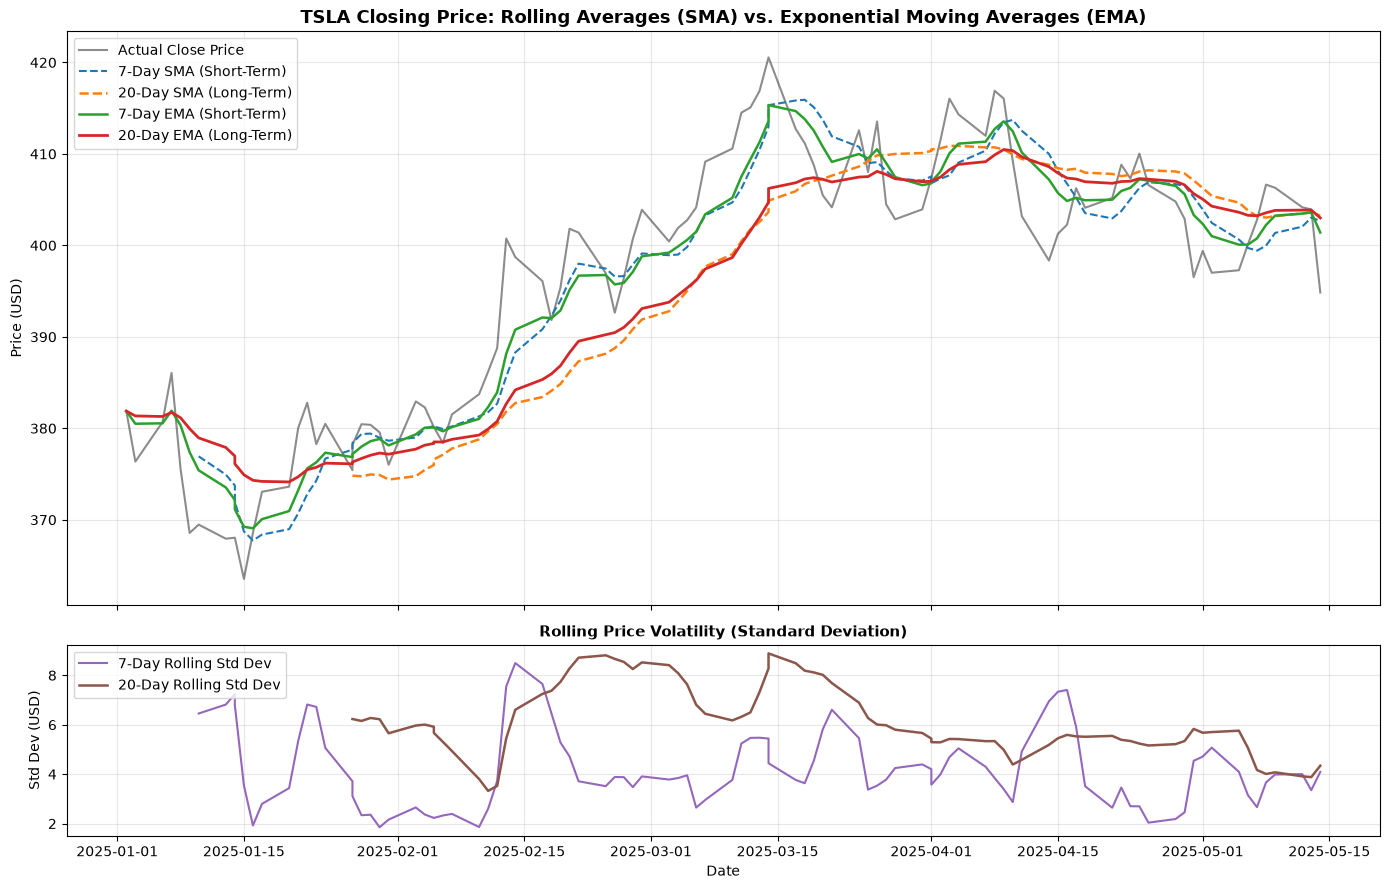

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Subplot 1: Closing Price vs. SMA & EMA Trends
ax1.plot(df['Date'], df['Close'], label='Actual Close Price', color='black', alpha=0.45, linewidth=1.5)
ax1.plot(df['Date'], df['SMA_7'], label='7-Day SMA (Short-Term)', color='#1f77b4', linestyle='--', linewidth=1.5)
ax1.plot(df['Date'], df['SMA_20'], label='20-Day SMA (Long-Term)', color='#ff7f0e', linestyle='--', linewidth=1.8)
ax1.plot(df['Date'], df['EMA_7'], label='7-Day EMA (Short-Term)', color='#2ca02c', linewidth=1.8)
ax1.plot(df['Date'], df['EMA_20'], label='20-Day EMA (Long-Term)', color='#d62728', linewidth=2.0)

ax1.set_title('TSLA Closing Price: Rolling Averages (SMA) vs. Exponential Moving Averages (EMA)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Price (USD)')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Subplot 2: Rolling Volatility (Standard Deviation)
ax2.plot(df['Date'], df['Rolling_Std_7'], label='7-Day Rolling Std Dev', color='#9467bd', linewidth=1.5)
ax2.plot(df['Date'], df['Rolling_Std_20'], label='20-Day Rolling Std Dev', color='#8c564b', linewidth=1.8)
ax2.set_title('Rolling Price Volatility (Standard Deviation)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Std Dev (USD)')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()